# Concept discovery in public digit images

We use **1,000 public handwritten digit images**, with ten one-versus-rest digit outcomes and stratified 700 / 150 / 150 splits. Original 8×8 grayscale pixels are converted to RGB before standard DINOv3 preprocessing. This is a software and discovery illustration, not a medical or handwriting benchmark; writers are not explicitly separated.

Source: [scikit-learn optical digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html). Image selection and splits are fixed with seed 42.

Both demos use **8,192 dictionary entries**, the package's default dictionary width. The CPU example uses a coarse candidate grid and a 2,000-step training budget. The first tested k reaching validation R²≥0.85 defines k₀; R²≥0.90 allows k≤2k₀, and R²≥0.95 allows k≤3k₀. Selection uses validation reconstruction, not test outcomes. Initial encoder gain is calibrated using training inputs only.

From a Glyph checkout, install `pip install -e ".[hf]"` and open this notebook. Approved access and a configured HF login are needed for [`facebook/dinov3-vits16-pretrain-lvd1689m`](https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m). Model revision is pinned. No author research data or LLM key is used.

The recorded execution below reloads a real local run when available; a fresh checkout follows the raw-input fitting branch. Embeddings were extracted with Glyph's HF adapter and the actual pretrained weights. The local saved models and full input caches are excluded from Git.


In [1]:
from pathlib import Path
import json, os, warnings
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from glyph import Glyph

repo = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/dinov3_digits.py").is_file())
os.chdir(repo)
from examples.dinov3_digits import prepare, make_glyph, summarize, report
torch.set_num_threads(8)
warnings.filterwarnings("ignore", category=FutureWarning, module=r"sklearn\..*")

# Optional recorded run. Absent on a fresh checkout, which computes a new run.
saved_run = repo / 'demo_outputs/digits_8192_20261027T013253465876/runs/20261027T013253Z-4d28277a6f'
output = repo / 'demo_outputs/digits_8192_20261027T013253465876'
output.mkdir(parents=True, exist_ok=True)
use_saved_run = saved_run.is_dir()
print("Reloading recorded run" if use_saved_run else "Starting from public raw inputs")


/dataNAS/people/rholland/micromamba/envs/venv_torch/lib/python3.11/site-packages/lightning_fabric/__init__.py:40: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


Reloading recorded run


## 1. Public inputs and labels

The helper selects inputs independently of outcome labels. Labels stratify the patient/image splits.


split
test     150
train    700
val      150


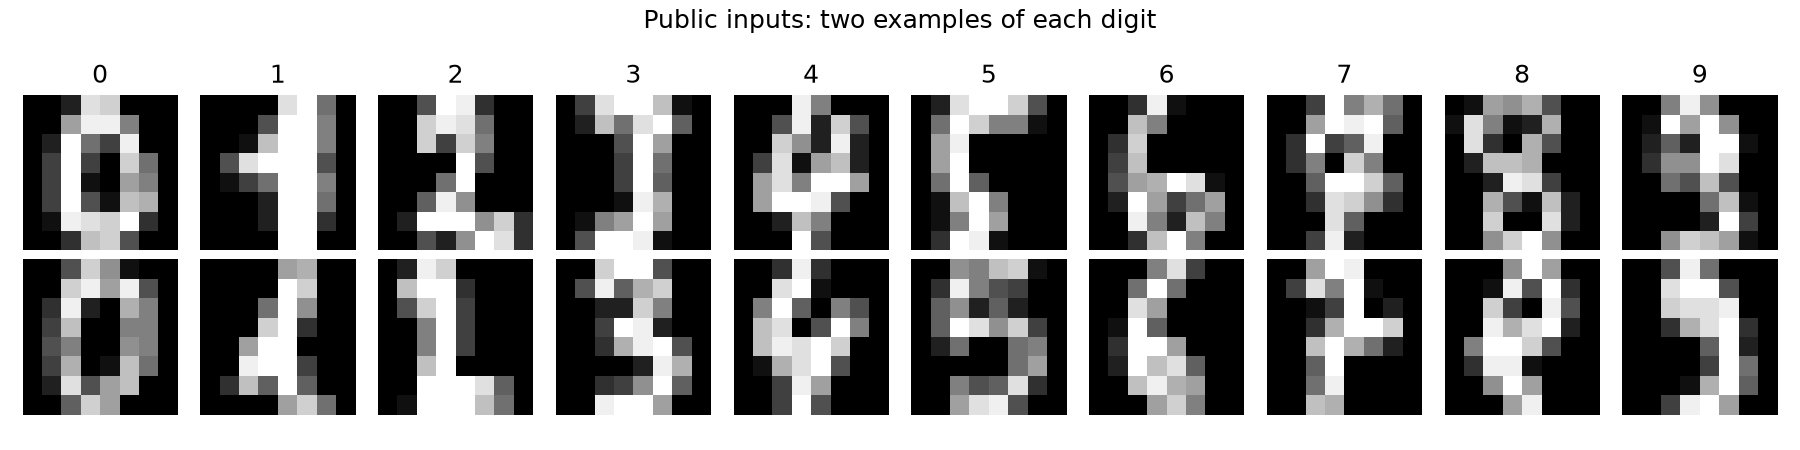

In [2]:
if use_saved_run:
    glyph = Glyph.load_run(saved_run, device="cpu")
    metadata = Path(glyph.cfg.data.metadata)
else:
    metadata_file = output / "inputs/metadata.csv"
    metadata = metadata_file if metadata_file.exists() else prepare(output / "inputs")
    glyph = make_glyph(metadata, output / "runs")

frame = pd.read_csv(metadata)
print(frame.groupby("split").size().to_string())
display(Image(filename=str(metadata.parent / "inputs.png"), width=900))


## 2. Extract embeddings and learn the full-width dictionary

On a fresh run, `fit` extracts DINOv3 embeddings and learns the dictionary. Reloading a completed run skips extraction and fitting. The table reports every tested k.


In [3]:
if not use_saved_run:
    glyph.fit()
selection = glyph.sae_models["image_path"].selection_report
assert selection["dictionary_size"] == 8192
print("Dictionary entries:", selection["dictionary_size"])
print("Selected k:", selection["selected_top_k"])
print("Validation R²:", selection["selected_validation_r2"])
print(pd.DataFrame(selection["tried"])[["top_k", "validation_r2"]].to_string(index=False))


Dictionary entries: 8192
Selected k: 64
Validation R²: 0.8677328144859944
 top_k  validation_r2
     8       0.748525
    16       0.796953
    32       0.833679
    64       0.867733
   128       0.897608
   192       0.915209


## 3. Test associations and create the explorer

The map shows all training-active concepts, preserving their original indices in the 8,192-entry dictionary. Bonferroni correction uses the saved testing family. No automated interpretation or confounder adjustment is requested.


Node area is proportional to activation prevalence, with a tiny floor and a common density adjustment. Correlation lines are visible by default, capped at eight per concept.

Node area is proportional to activation prevalence, with a tiny floor and a common density adjustment. Correlation lines are visible by default, capped at eight per concept.

In [4]:
if glyph.phewas_results is None:
    glyph.hypothesis_search()
html_path = repo / 'demo_outputs/prevalence_sizing_dinov3_digits_20261027T214254/explorer.html'
if not html_path.exists():
    html_path = Path(glyph.visualize(split="train")[0])
print("Explorer:", html_path)
summary = summarize(glyph, output)
print("Training-active concepts:", summary["alive_concepts"])


Explorer: /dataNAS/people/rholland/Glyph/demo_outputs/prevalence_sizing_dinov3_digits_20261027T214254/explorer.html


Training-active concepts: 1629


## 4. Generate the visual brief

The PDF includes the entire active concept space, followed by one page per selected concept with its local map, exact statistics and actual activating training/held-out images together. Images are selected by activation, without outcome-based selection; this is not semantic interpretation validation.


Concept pages show a zero-activation image, then 33rd/66th/100th percentiles among positive training activations, followed by the high-activation tail. The HTML report has expandable tail panels. Predictor checkpoints and penalties use validation only, with patience 20 and separate literature/Glyph block penalties. Comparison brackets show exploratory paired-bootstrap p-values and stars. [Expandable HTML report](report_files/report.html).

Concept pages show a zero-activation image, then 33rd/66th/100th percentiles among positive training activations, followed by the high-activation tail. The HTML report has expandable tail panels. Predictor checkpoints and penalties use validation only, with patience 20 and separate literature/Glyph block penalties. Comparison brackets show exploratory paired-bootstrap p-values and stars. [Expandable HTML report](report_files/report.html).

{'n_concepts': 1629, 'n_significant_pairs': 680, 'n_comparable_hits': 545, 'n_reproduced_hits': 24}


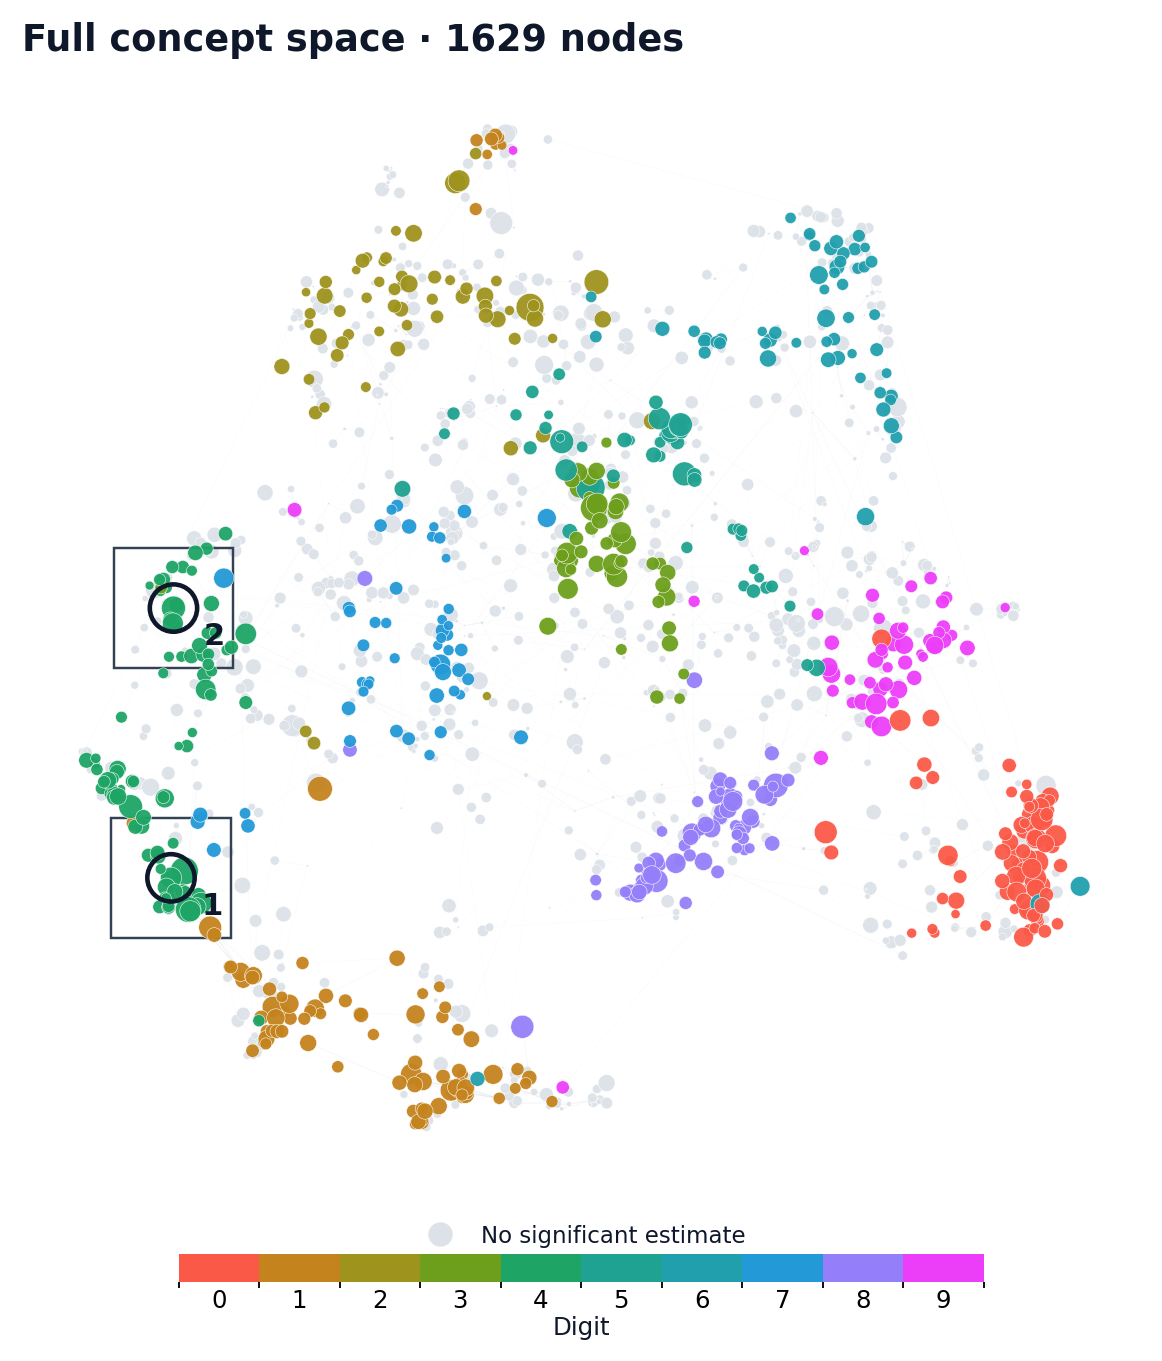

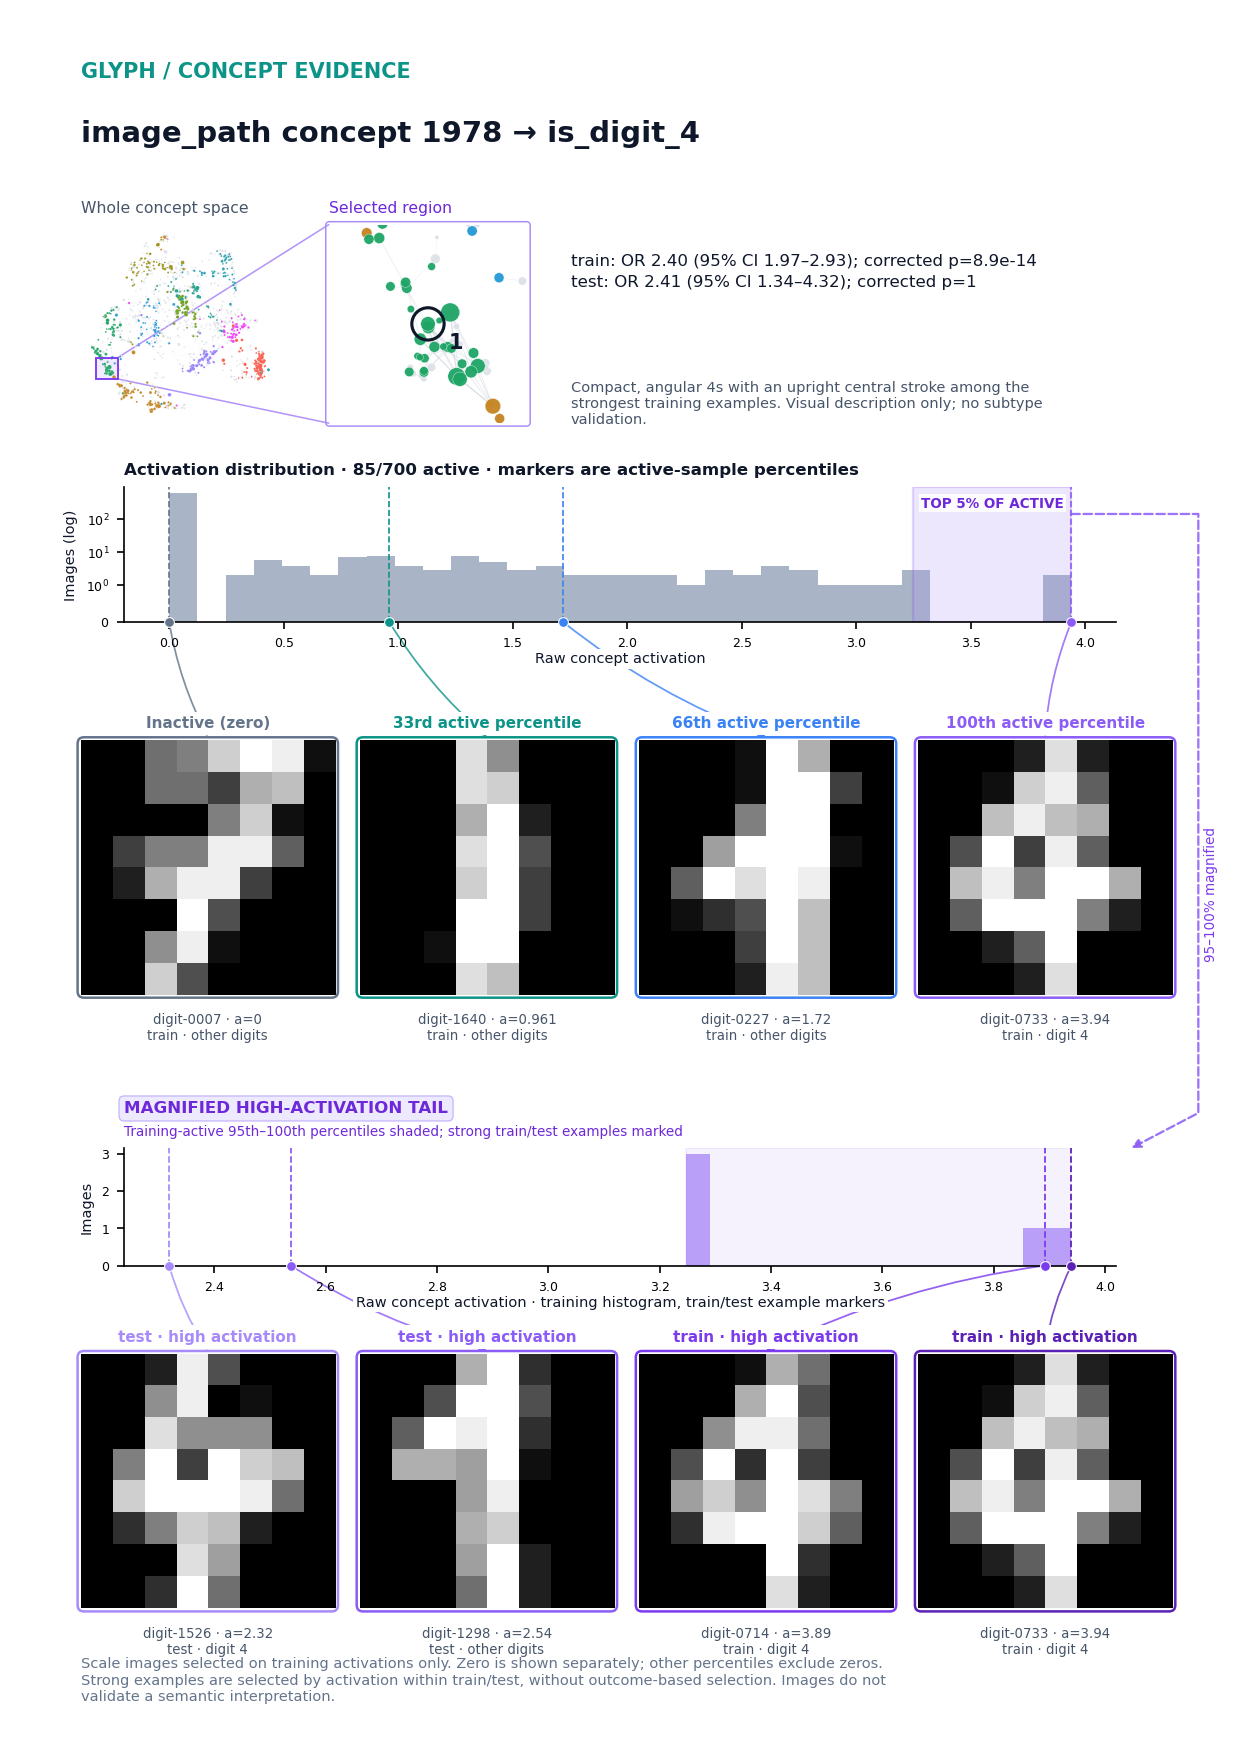

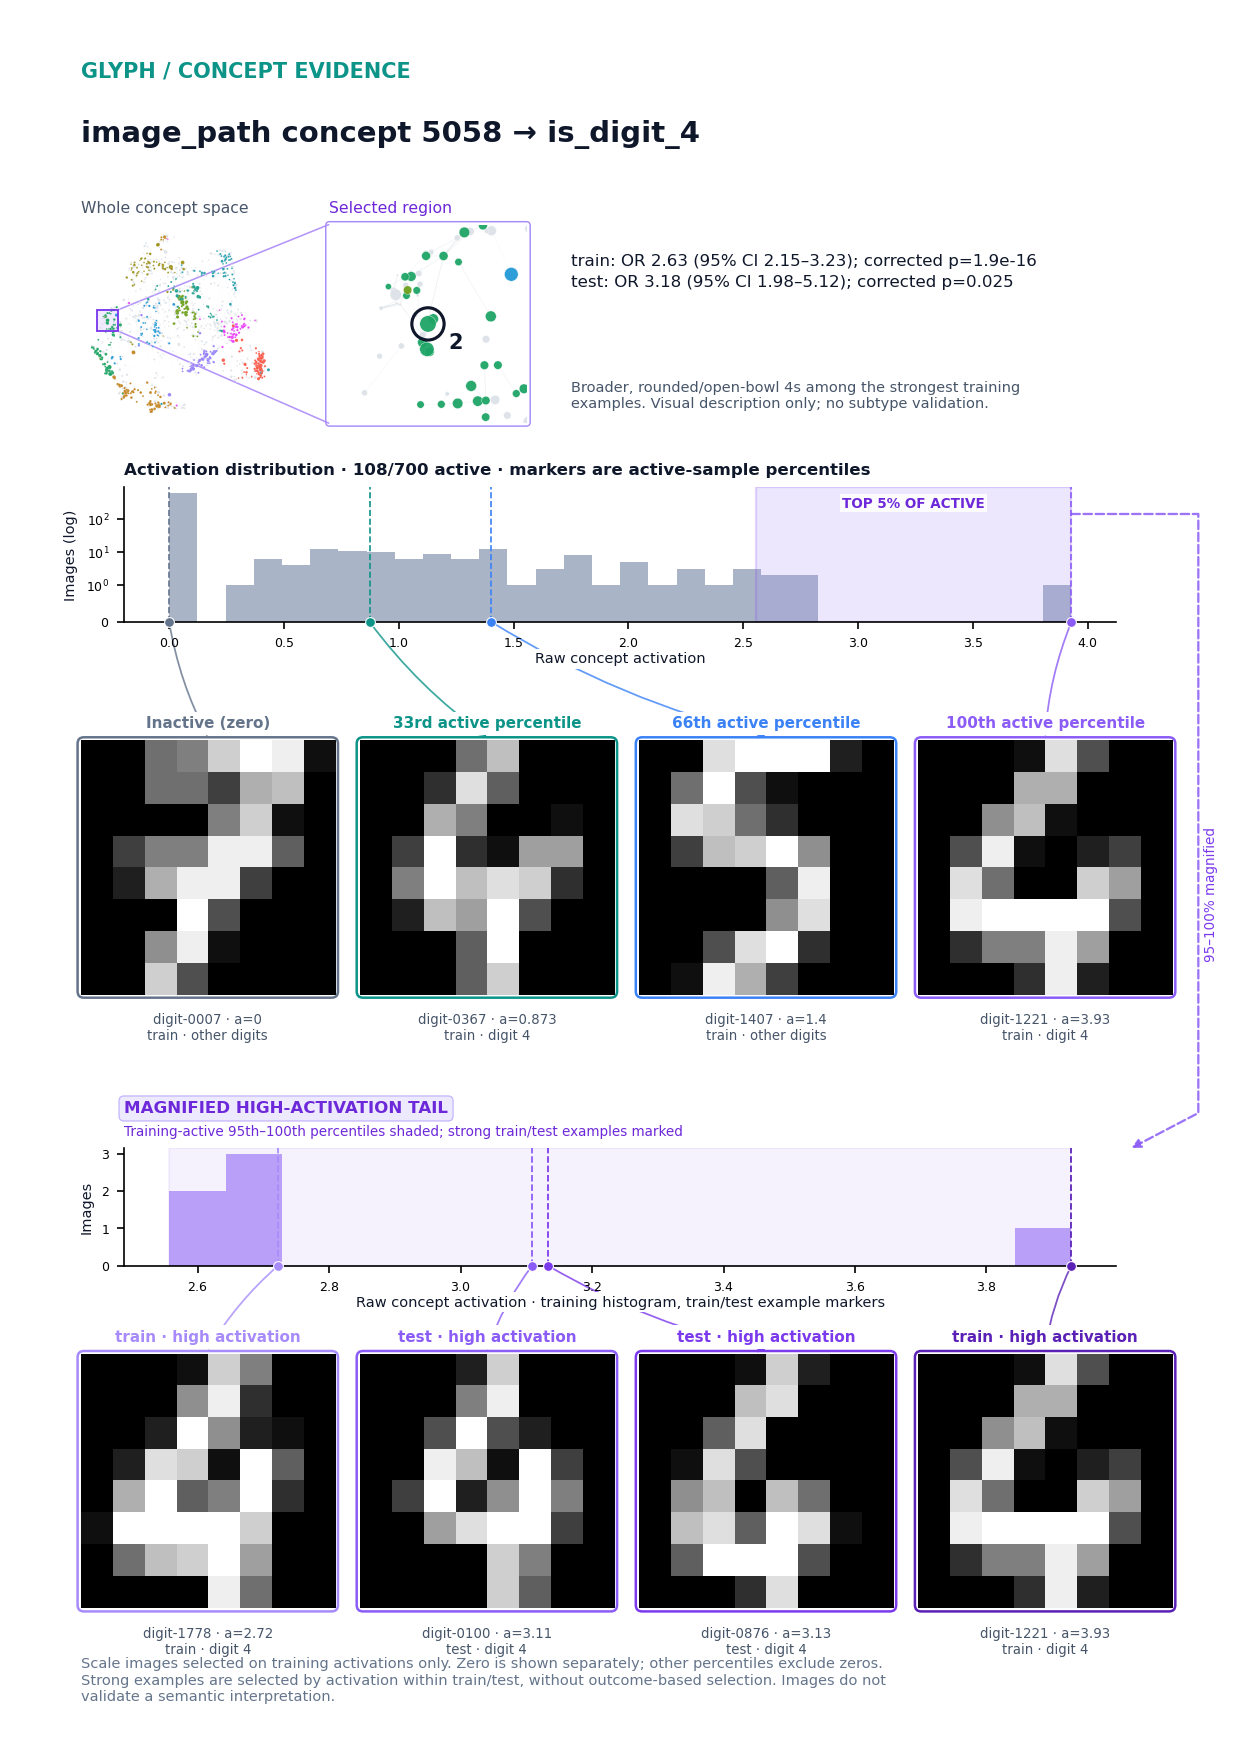

PDF: /dataNAS/people/rholland/Glyph/demo_outputs/prevalence_sizing_dinov3_digits_20261027T224231/report_files/report.pdf


In [5]:
report_dir = repo / 'demo_outputs/prevalence_sizing_dinov3_digits_20261027T224231/report_files'
if not (report_dir / "report.pdf").exists():
    report(glyph.run_dir, report_dir)
facts = json.loads((report_dir / "facts.json").read_text())
print({key: facts[key] for key in ["n_concepts", "n_significant_pairs", "n_comparable_hits", "n_reproduced_hits"]})
display(Image(filename=str(report_dir / "concept_space.png"), width=900))
for i, item in enumerate(facts["image_examples"]):
    display(Image(filename=str(report_dir / f"concept_{i+1}.png"), width=850))
print("PDF:", report_dir / "report.pdf")


## 5. Reload the saved dictionary

Reuse its stored parameters and normalization. This check uses the same CPU thread setting as the recorded run.


In [6]:
loaded = Glyph.load_run(glyph.run_dir, device="cpu")
for split, data in glyph.embeddings.items():
    extracted = loaded.encode_embeddings(data["embeddings"]["image_path"], modality="image_path")
    torch.testing.assert_close(extracted, glyph.sae_features["image_path"][split], rtol=0, atol=0)
print("Exact saved activation reload passed")


Exact saved activation reload passed


## View the curated files

[Interactive explorer](explorer.html) · [PDF report](report.pdf) · [Markdown report](report_files/report.md)

GitHub renders the notebook and PDF. Download the self-contained HTML and open it locally for interaction. The report distinguishes discovery significance, held-out association estimates and predictive model performance. No new biological discovery or external clinical validation is established by this demo.
